##              Real-World Pedal Energy Harvesting 


###        PROBLEM STATEMENT

Estimate the total energy that can be harvested from human footsteps in crowded areas (e.g., metro stations, malls, universities) and assess its contribution toward sustainable smart-city energy solutions.

### Importing Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

from warnings import filterwarnings
filterwarnings("ignore")

### Dataset Overview

#### Dataset Details -1
* **Dataset Name** :**Footstep Power Generation Tile Data**
* **Source** : https://www.kaggle.com/datasets/ishanshrivastava28/footstep-power-generation-tile-data
* **File Format** : .csv

#### Dataset Description
The Footstep Power Generation Tile data contains 3 numerical features voltage(V),current(mA),and weight(kgs).1 categorical feature that is the step location of the person on the square tile-center,edge,corner.It also contains the null values,Null values are occurred due to loose connections of sensors.

#### Feature Description
* **Time_sec**:The Timestamp since the start of the measurement
* **Pedal_RPM**:Revolution per minute of the Pedal
* **Torque_Nm**:Mechanical torque applied to the Pedal
* **Voltage_V**:Voltage generated by the pedal power generator
* **Current_A**:Electric current generated
* **Power_W**:Electrical power output of the system



#### Loading the Dataset

In [2]:
df = pd.read_csv("dataset_10000.csv")

### Exploring the dataset

In [3]:
print(df.shape)

(10000, 5)


In [4]:
df.head(10)

,voltage,current,weight,step_location,power
0,7.52,50.89,53.0,Center,0.38
1,16.10,51.45,59.0,Edge,0.83
2,21.70,54.90,63.0,Center,1.19
3,6.05,52.86,54.0,Edge,0.32
4,33.70,52.06,76.0,Center,1.75
5,26.39,54.59,69.0,Edge,1.44
6,29.80,49.55,73.0,Center,1.48
7,19.70,53.35,63.0,Center,1.05
8,26.50,48.64,72.0,Center,1.29
9,30.80,51.56,75.0,Corner,1.59


In [5]:
df.columns

Index(['voltage', 'current', 'weight', 'step_location', 'power'], dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   voltage        10000 non-null  float64
 1   current        10000 non-null  float64
 2   weight         10000 non-null  float64
 3   step_location  10000 non-null  object 
 4   power          10000 non-null  float64
dtypes: float64(4), object(1)
memory usage: 390.8+ KB


In [7]:
df.describe()

,voltage,current,weight,power
count,10000.000000,10000.000000,10000.000000,10000.000000
mean,19.374047,47.705415,65.627730,0.975416
std,10.900682,11.694643,9.280152,0.561335
min,0.000000,0.000000,39.600000,0.000000
25%,10.700000,46.890000,59.100000,0.536000
50%,20.450000,49.810000,65.700000,1.028000
75%,26.232500,52.900000,71.700000,1.333000
max,58.990000,60.340000,99.000000,3.515000


In [8]:
df.isnull().sum()

voltage          0
current          0
weight           0
step_location    0
power            0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(200)

In [10]:
df.dtypes

voltage          float64
current          float64
weight           float64
step_location     object
power            float64
dtype: object

# Exploritary Data Anaylsis

## UniVariate Anaylsis

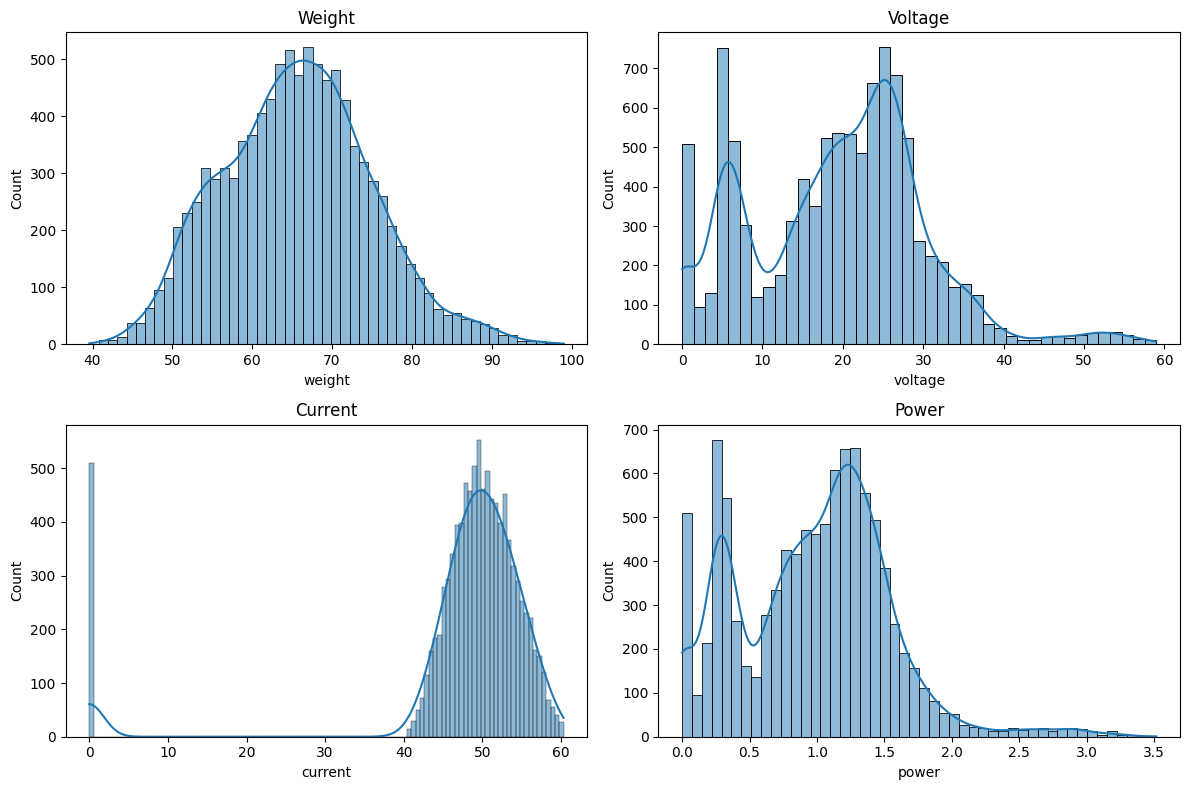

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(df["weight"], kde=True, ax=axes[0,0])
axes[0,0].set_title("Weight")

sns.histplot(df["voltage"], kde=True, ax=axes[0,1])
axes[0,1].set_title("Voltage")

sns.histplot(df["current"], kde=True, ax=axes[1,0])
axes[1,0].set_title("Current")

sns.histplot(df["power"], kde=True, ax=axes[1,1])
axes[1,1].set_title("Power")

plt.tight_layout()
plt.show()

## Description

The figure presents the **univariate distribution** of the four numerical features in the energy harvesting dataset: **Weight, Voltage, Current, and Power**. Histograms combined with Kernel Density Estimation (KDE) curves are used to visualize the distribution, spread, central tendency, and potential outliers of each feature.


## Analysis

### Weight
- The weight values range approximately from **40 kg to 100 kg**.
- Most observations are concentrated between **60 kg and 72 kg**, with the peak around **66–68 kg**.
- The distribution is close to a **bell-shaped (normal) distribution**, indicating a balanced representation of different user weights.
- A slight right skew is observed due to a few heavier individuals above **85 kg**.
- The smooth KDE curve confirms that the synthetic data preserves a realistic weight distribution.



### Voltage
- Voltage values range from **0 V to nearly 60 V**.
- The majority of samples lie between **18 V and 30 V**, with the highest density around **24–26 V**.
- A smaller cluster of low-voltage observations (around **5 V**) is visible, representing low-energy footstep events.
- The distribution is moderately right-skewed with a few high-voltage observations extending beyond **40 V**.
- The voltage distribution reflects varying footstep intensities and energy generation conditions.



### Current
- Most current values are concentrated between **45 μA and 55 μA**.
- The distribution is approximately normal with the highest density around **50 μA**.
- A small spike at **0 μA** represents a few zero-current observations recorded during minimal or ineffective energy generation.
- Apart from these zero values, the current measurements remain consistent across the dataset.
- The narrow spread indicates stable current generation under normal operating conditions.



### Power
- Power values range from approximately **0 mW to 3.5 mW**.
- Most generated power falls between **0.8 mW and 1.5 mW**, with the peak around **1.2 mW**.
- A small group of low-power observations exists below **0.5 mW**, corresponding to weaker footsteps.
- The distribution is positively skewed because only a limited number of footsteps produce exceptionally high power.
- The KDE curve indicates that the majority of energy harvesting events generate moderate power output.


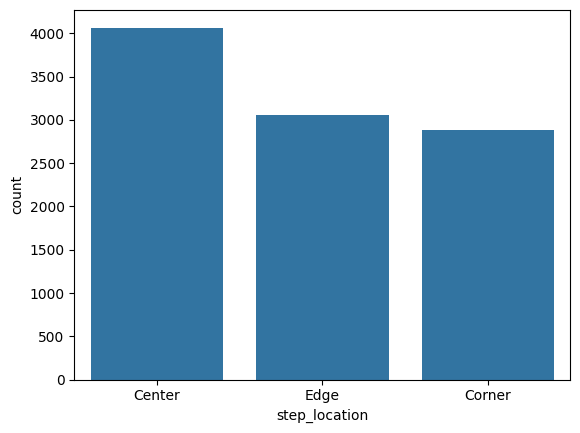

In [12]:
sns.countplot(data=df, x="step_location")
plt.show()

## Description

The bar chart illustrates the **frequency distribution of footstep locations** recorded in the dataset. It shows the number of observations collected for the three categorical step positions: **Center, Edge, and Corner**. This visualization helps understand the representation of each footstep category before performing machine learning.



## Analysis

### Center
- The **Center** location contains the highest number of observations, with approximately **4,000+ samples**.
- This indicates that most footsteps were recorded at the center of the piezoelectric tile.
- The larger sample size provides better learning opportunities for the machine learning model for this category.


### Edge
- The **Edge** category contains approximately **3,000 observations**.
- Although fewer than the Center category, it still represents a substantial portion of the dataset.
- This balanced representation allows the model to learn energy generation patterns from edge footsteps effectively.



### Corner
- The **Corner** category has the lowest number of observations, with approximately **2,900 samples**.
- Despite being the smallest class, it still contains sufficient samples for meaningful analysis and prediction.
- The lower frequency reflects that corner footsteps occur less frequently in the generated dataset.


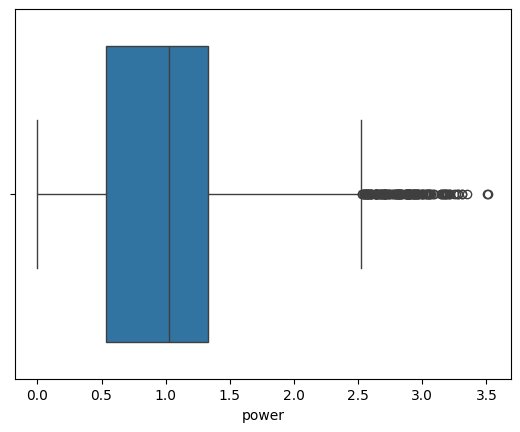

In [13]:
sns.boxplot(x=df["power"])
plt.show()

## Description

The box plot visualizes the **distribution of power generation** and helps identify the median, spread, variability, and potential outliers in the dataset. It provides a concise summary of how the generated power values are distributed.

## Analysis

### Median
- The median power generation is approximately **1.0 mW**, indicating that half of the observations produce power below this value and half above it.

### Data Spread
- The middle 50% of the power values (Interquartile Range) lies approximately between **0.6 mW and 1.3 mW**.
- This indicates that most footsteps generate a moderate amount of electrical power.

### Whiskers
- The whiskers extend from approximately **0.0 mW to 2.5 mW**, representing the majority of the observations within the normal range.

### Outliers
- Several observations above **2.5 mW** are identified as outliers.
- These correspond to high-energy footsteps that generated unusually large amounts of power.
- Such values are expected in real-world energy harvesting systems and were retained because they represent valid observations rather than measurement errors.

### Interpretation
- The dataset is positively skewed, with most power values concentrated at lower to moderate levels and only a few high-power events.
- The presence of outliers increases the realism of the dataset and enables machine learning models to learn both typical and exceptional power generation scenarios.

## Bi-Variate Analysis

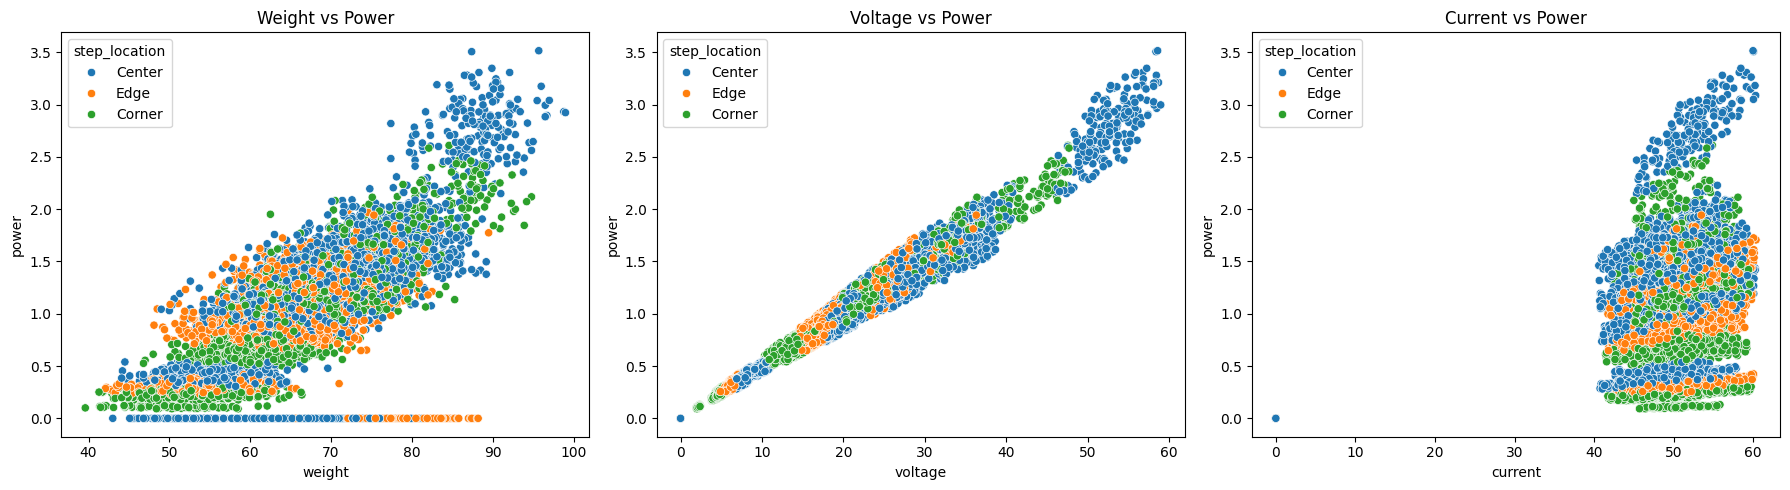

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(data=df, x="weight", y="power", hue="step_location", ax=axes[0])
axes[0].set_title("Weight vs Power")

sns.scatterplot( data=df, x="voltage", y="power", hue="step_location", ax=axes[1] )
axes[1].set_title("Voltage vs Power")

sns.scatterplot(data=df, x="current", y="power", hue="step_location", ax=axes[2])
axes[2].set_title("Current vs Power")

plt.tight_layout()
plt.show()

## Description

The scatter plots illustrate the relationship between **Weight, Voltage, and Current** with the target variable **Power**. Data points are color-coded based on **Step Location (Center, Edge, and Corner)**, allowing comparison of how footstep position influences power generation.

## Analysis

### Weight vs Power
- A clear positive relationship exists between **Weight** and **Power**, indicating that heavier users generally generate more electrical power.
- The **Center** step location consistently produces higher power values compared to **Edge** and **Corner** for similar weights.
- A few observations with zero power represent ineffective energy harvesting events.
- The increasing spread of points at higher weights suggests greater variability in power generation under heavier loads.

### Voltage vs Power
- **Voltage** exhibits an almost perfect positive linear relationship with **Power**.
- As voltage increases, the generated power also increases proportionally.
- The strong linear trend indicates that voltage is one of the most influential predictors for power generation.
- The three step locations largely overlap, showing that voltage influences power consistently across all footstep positions.

### Current vs Power
- Current values are concentrated within a relatively narrow range, while power varies considerably.
- A moderate positive relationship exists between **Current** and **Power**, although it is weaker than the relationship observed with voltage.
- The **Center** location generally achieves higher power values than the **Edge** and **Corner** locations at similar current levels.
- The wider vertical spread of points indicates that current alone cannot fully explain variations in generated power.

### Interpretation
- Among all three features, **Voltage shows the strongest relationship with Power**, followed by **Weight**, while **Current contributes comparatively less**.
- The color-coded visualization demonstrates that **Step Location** also influences power generation, with **Center** footsteps typically producing the highest energy output.
- These observations justify the selection of **Voltage, Weight, Current, and Step Location** as important input features for machine learning model development.

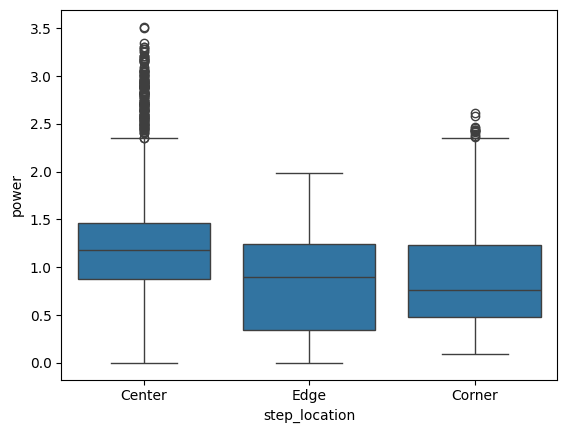

In [15]:
sns.boxplot(data=df, x="step_location", y="power")
plt.show()

## Description

The box plot compares the **distribution of power generation** across the three footstep locations: **Center, Edge, and Corner**. It summarizes the median, spread, variability, and presence of outliers for each stepping position, helping identify which location produces higher electrical power.

## Analysis

### Center
- The **Center** location has the highest median power generation among all three categories.
- The interquartile range (IQR) is relatively compact, indicating consistent power output.
- Numerous high-value outliers above **2.3 mW** are observed, representing footsteps that generated exceptionally high power.
- This suggests that stepping at the center of the piezoelectric tile is the most effective position for energy harvesting.

### Edge
- The **Edge** location exhibits a lower median power compared to the Center.
- Most power values are concentrated below **1.3 mW**, indicating moderate energy generation.
- The spread is relatively balanced with very few extreme outliers.
- This indicates that edge footsteps generate less power but maintain reasonable consistency.

### Corner
- The **Corner** location has the lowest median power generation among the three categories.
- The distribution shows moderate variability with most observations falling below **1.2 mW**.
- A few higher-value outliers are present, indicating that certain corner footsteps can still produce relatively high power.
- Overall, corner footsteps are less efficient for energy harvesting compared to center and edge positions.

### Interpretation
- The **Center** step location consistently produces higher power output than the **Edge** and **Corner** locations.
- The differences in median values indicate that footstep position has a significant influence on energy generation.
- The presence of valid outliers reflects natural variations in user weight and stepping force rather than data anomalies.
- These findings confirm that **Step Location** is an important feature for predicting power generation in the machine learning model.

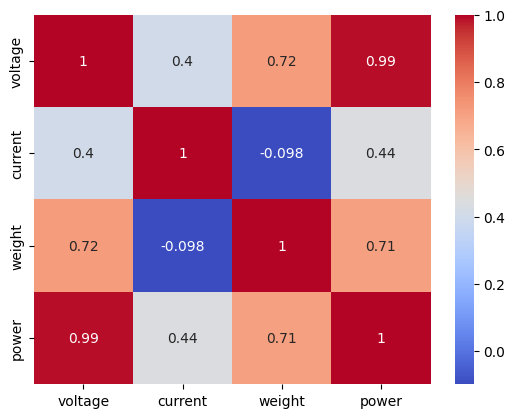

In [16]:
corr = df.corr(numeric_only=True)

sns.heatmap(corr, annot=True, cmap="coolwarm" )
plt.show()

## Description

The correlation heatmap illustrates the **pairwise relationships** between the numerical features: **Voltage, Current, Weight, and Power**. Correlation coefficients range from **-1 to +1**, where values closer to **+1** indicate a strong positive relationship, values near **0** indicate little or no relationship, and values closer to **-1** indicate a negative relationship.

## Analysis

### Voltage vs Power
- Voltage exhibits an **extremely strong positive correlation (0.99)** with Power.
- This indicates that as voltage increases, the generated power also increases almost proportionally.
- Voltage is the most influential predictor for power generation in the dataset.

### Weight vs Power
- Weight shows a **strong positive correlation (0.71)** with Power.
- Heavier users generally produce greater mechanical force, resulting in higher electrical power generation.
- This confirms that user weight is an important factor affecting energy harvesting.

### Current vs Power
- Current has a **moderate positive correlation (0.44)** with Power.
- Although current contributes to power generation, its influence is weaker compared to voltage and weight.
- This suggests that current alone is not sufficient for accurately predicting power output.

### Weight vs Voltage
- Weight and Voltage exhibit a **strong positive correlation (0.72)**.
- Increased user weight generally leads to higher voltage generation due to greater applied pressure on the piezoelectric tile.

### Weight vs Current
- Weight has a **very weak negative correlation (-0.098)** with Current.
- This indicates that user weight has minimal influence on the current generated.
- The relationship is weak enough to be considered practically insignificant.

### Voltage vs Current
- Voltage and Current show a **moderate positive correlation (0.40)**.
- This suggests that higher voltage values are generally accompanied by slightly higher current values, although the relationship is not very strong.

### Interpretation
- **Voltage** is the strongest predictor of power generation, followed by **Weight**.
- **Current** provides additional information but contributes less compared to the other features.
- The correlation matrix confirms that the selected features have meaningful relationships with the target variable, making them suitable for machine learning model development.

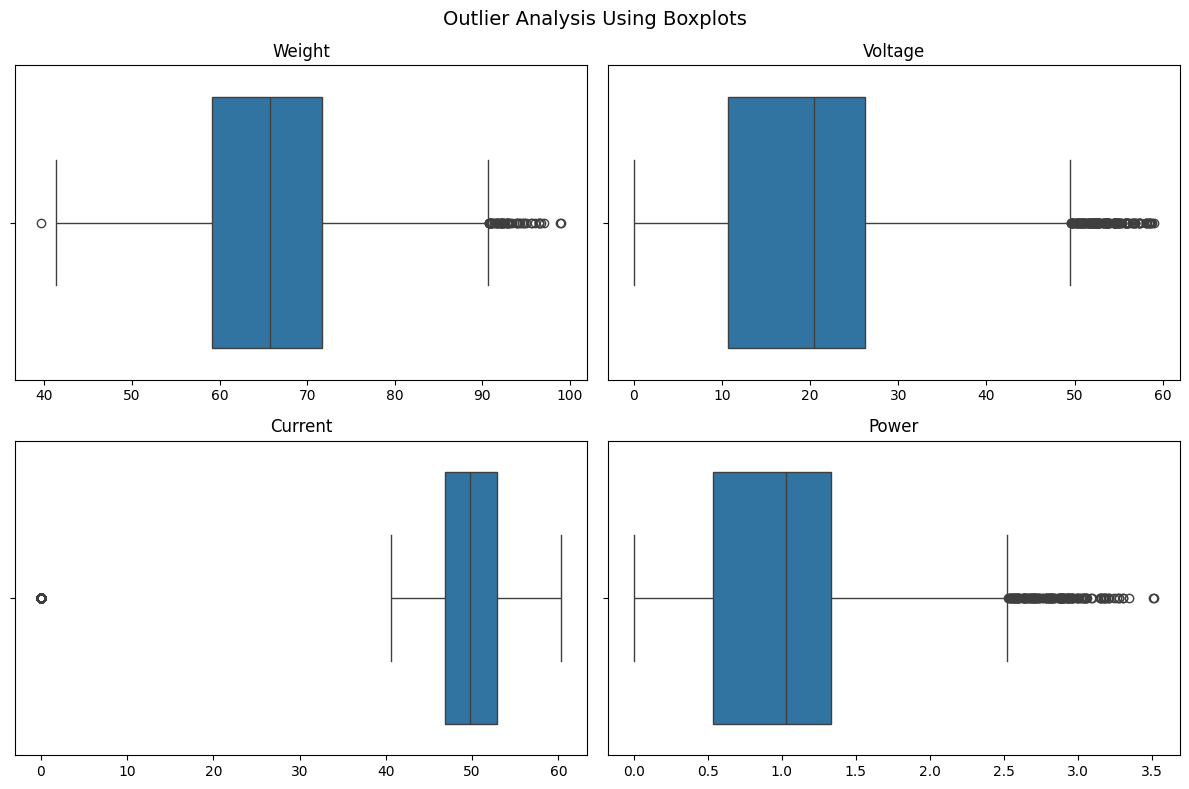

In [17]:
cols = ["weight", "voltage", "current", "power"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.ravel(), cols):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col.capitalize())
    ax.set_xlabel("")

fig.suptitle("Outlier Analysis Using Boxplots", fontsize=14)
plt.tight_layout()
plt.show()


## Description

The figure presents **box plots** for the four numerical features: **Weight, Voltage, Current, and Power**. These plots summarize the distribution of each variable by displaying the median, interquartile range (IQR), overall spread, and potential outliers. Box plots are useful for detecting extreme observations and assessing the variability of each feature before model development.

## Analysis

### Weight
- The median weight is approximately **66 kg**, with most observations ranging between **58 kg and 72 kg**.
- The majority of participants fall within a consistent weight range, indicating a well-distributed dataset.
- A few observations above **90 kg** are identified as outliers, representing heavier individuals.
- These outliers are realistic and were retained as they reflect genuine variations in user weight.

### Voltage
- The median voltage is approximately **20–22 V**.
- Most voltage values lie between **12 V and 27 V**, indicating stable energy generation under normal conditions.
- Several observations above **50 V** appear as outliers, corresponding to high-energy harvesting events.
- These values are expected when greater force is applied to the piezoelectric tile.

### Current
- Current values are highly concentrated around **50 μA**, showing very low variability.
- The interquartile range is narrow, indicating consistent current generation across most observations.
- A small number of zero-current observations appear as outliers, representing ineffective or minimal energy harvesting events.
- Apart from these values, the current measurements remain stable throughout the dataset.

### Power
- The median generated power is approximately **1.0 mW**.
- Most power values fall between **0.5 mW and 1.3 mW**, indicating moderate energy generation.
- Multiple observations above **2.5 mW** are identified as outliers, representing high-power footsteps.
- These outliers were retained because they reflect valid high-energy events rather than measurement errors.

### Interpretation
- The box plots indicate that all numerical features exhibit reasonable distributions with a limited number of outliers.
- The detected outliers correspond to realistic variations in user weight and footstep intensity, making them valuable for improving model robustness.
- Since the outliers represent genuine observations rather than erroneous data, they were retained for machine learning model development.


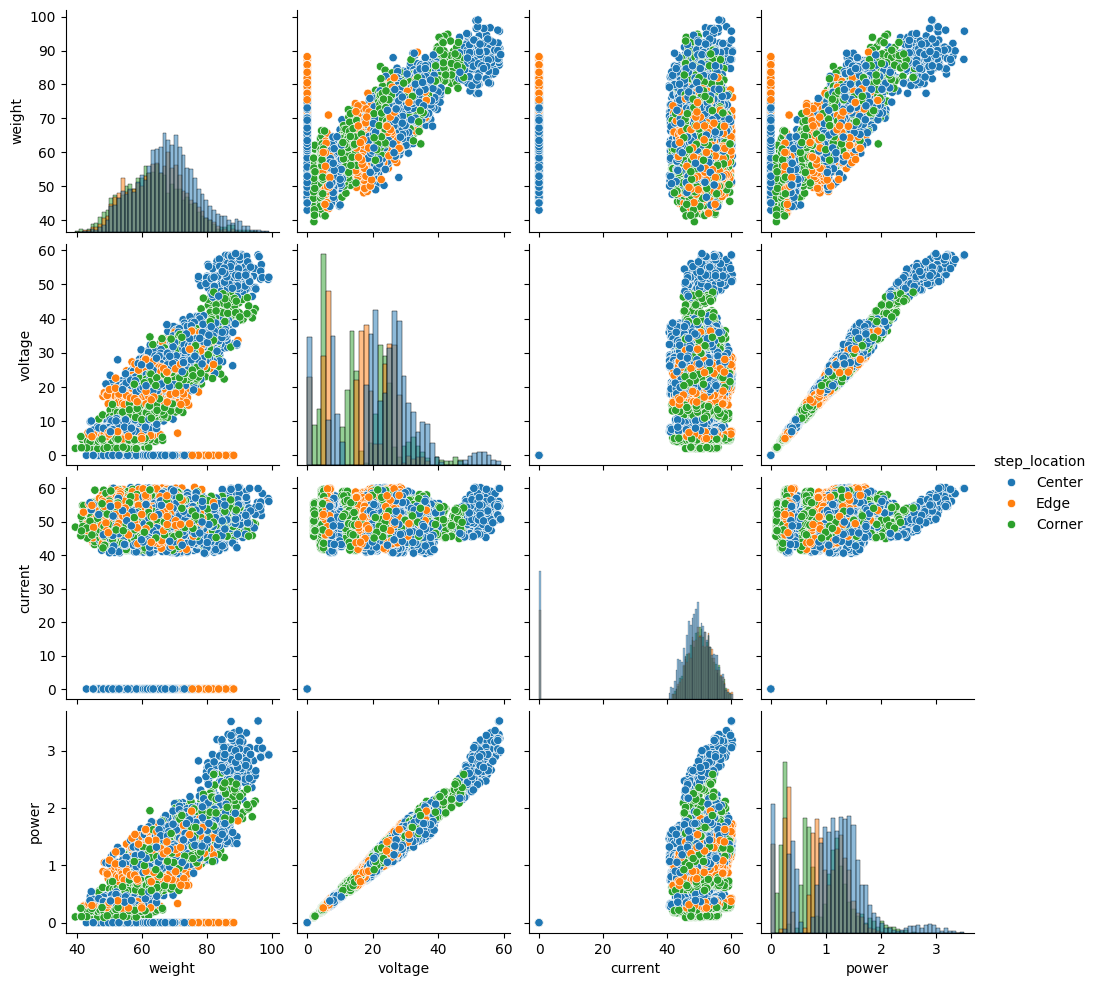

In [18]:
sns.pairplot(df, vars=["weight", "voltage", "current", "power"],
    hue="step_location",
    diag_kind="hist")
plt.show()

## Description

The pair plot provides a comprehensive view of the relationships among **Weight, Voltage, Current, and Power**. The diagonal plots show feature distributions, while the scatter plots illustrate pairwise relationships. Different colors represent the three **Step Locations** (Center, Edge, and Corner).

## Analysis

- **Voltage and Power** exhibit a very strong positive linear relationship.
- **Weight** shows a positive correlation with both **Voltage** and **Power**.
- **Current** has a weaker relationship with the other numerical features.
- The feature distributions are generally well-balanced with a few realistic outliers.
- The three step locations overlap but show slight differences in power generation patterns.
- The pair plot confirms that the selected features are suitable for predictive machine learning models.

# Feature Engineering

## Feature 1 : Weight class

<B> Purpose :</B> Categorizes users into weight groups to help the model learn weight-based energy generation patterns.

In [19]:
df["weight_class"] = pd.cut(df["weight"],bins=[0, 60, 75, 100],labels=["Light", "Medium", "Heavy"])

## Feature 2 : Step Zone

<B> Purpose :</B> Converts categorical step locations into meaningful positional zones for improved spatial interpretation.

In [20]:
zone_map = {
    "Center": "Optimal",
    "Edge": "Peripheral",
    "Corner": "Extreme"
}

df["step_zone"] = df["step_location"].map(zone_map)

## Feature 3 : Pressure Index

<B> Purpose :</B> Estimates the effective force applied on the tile by combining user weight and step location.

In [21]:
location_factor = {
    "Center": 1.0,
    "Edge": 0.8,
    "Corner": 0.6
}

df["pressure_index"] = (df["weight"] * df["step_location"].map(location_factor))

## Feature 4 : Current Utilization

<B> Purpose :</B> Measures the relative current generation efficiency compared to the maximum observed current.

In [22]:
df["current_utilization"] = (df["current"] / df["current"].max())

## Feature 5 : Voltage Stability

<B> Purpose :</B> Indicates how closely a voltage value aligns with the normal operating range of the system.

In [23]:
df["voltage_stability"] = (1 - abs(df["voltage"] - df["voltage"].mean())/ df["voltage"].max())

## Feature 6 : Power Category
<B> Purpose :</B> Groups power output into low, medium, and high generation levels for easier pattern analysis.

In [24]:
df["power_category"] = pd.qcut(df["power"],q=3,labels=["Low", "Medium", "High"])

## Feature 7 : Efficiency Score
<B> Purpose :</B> Provides a combined performance indicator using voltage stability and current utilization.

In [25]:
df["efficiency_score"] = (0.7 * df["voltage_stability"]+0.3 * df["current_utilization"]) * 100

In [26]:
df.head(10)

,voltage,current,weight,step_location,power,weight_class,step_zone,pressure_index,current_utilization,voltage_stability,power_category,efficiency_score
0,7.52,50.89,53.0,Center,0.38,Light,Optimal,53.0,0.843387,0.799050,Low,81.235116
1,16.10,51.45,59.0,Edge,0.83,Light,Peripheral,47.2,0.852668,0.944498,Medium,91.694925
2,21.70,54.90,63.0,Center,1.19,Medium,Optimal,63.0,0.909844,0.960570,Medium,94.535253
3,6.05,52.86,54.0,Edge,0.32,Light,Peripheral,43.2,0.876036,0.774130,Low,80.470203
4,33.70,52.06,76.0,Center,1.75,Heavy,Optimal,76.0,0.862778,0.757146,High,78.883553
5,26.39,54.59,69.0,Edge,1.44,Medium,Peripheral,55.2,0.904707,0.881065,High,88.815777
6,29.80,49.55,73.0,Center,1.48,Medium,Optimal,73.0,0.821180,0.823259,High,82.263528
7,19.70,53.35,63.0,Center,1.05,Medium,Optimal,63.0,0.884156,0.994474,Medium,96.137904
8,26.50,48.64,72.0,Center,1.29,Medium,Optimal,72.0,0.806099,0.879201,High,85.727009
9,30.80,51.56,75.0,Corner,1.59,Medium,Extreme,45.0,0.854491,0.806307,High,82.076223


In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype   
---  ------               --------------  -----   
 0   voltage              10000 non-null  float64 
 1   current              10000 non-null  float64 
 2   weight               10000 non-null  float64 
 3   step_location        10000 non-null  object  
 4   power                10000 non-null  float64 
 5   weight_class         10000 non-null  category
 6   step_zone            10000 non-null  object  
 7   pressure_index       10000 non-null  float64 
 8   current_utilization  10000 non-null  float64 
 9   voltage_stability    10000 non-null  float64 
 10  power_category       10000 non-null  category
 11  efficiency_score     10000 non-null  float64 
dtypes: category(2), float64(8), object(2)
memory usage: 801.2+ KB


In [28]:
df.describe()

,voltage,current,weight,power,pressure_index,current_utilization,voltage_stability,efficiency_score
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,19.374047,47.705415,65.627730,0.975416,54.353824,0.790610,0.852570,83.398205
std,10.900682,11.694643,9.280152,0.561335,14.507984,0.193812,0.111396,11.207556
min,0.000000,0.000000,39.600000,0.000000,23.760000,0.000000,0.328429,47.009946
25%,10.700000,46.890000,59.100000,0.536000,42.240000,0.777096,0.777513,79.589674
50%,20.450000,49.810000,65.700000,1.028000,53.840000,0.825489,0.879031,86.331784
75%,26.232500,52.900000,71.700000,1.333000,65.600000,0.876699,0.937007,90.636598
max,58.990000,60.340000,99.000000,3.515000,99.000000,1.000000,0.999931,99.354676


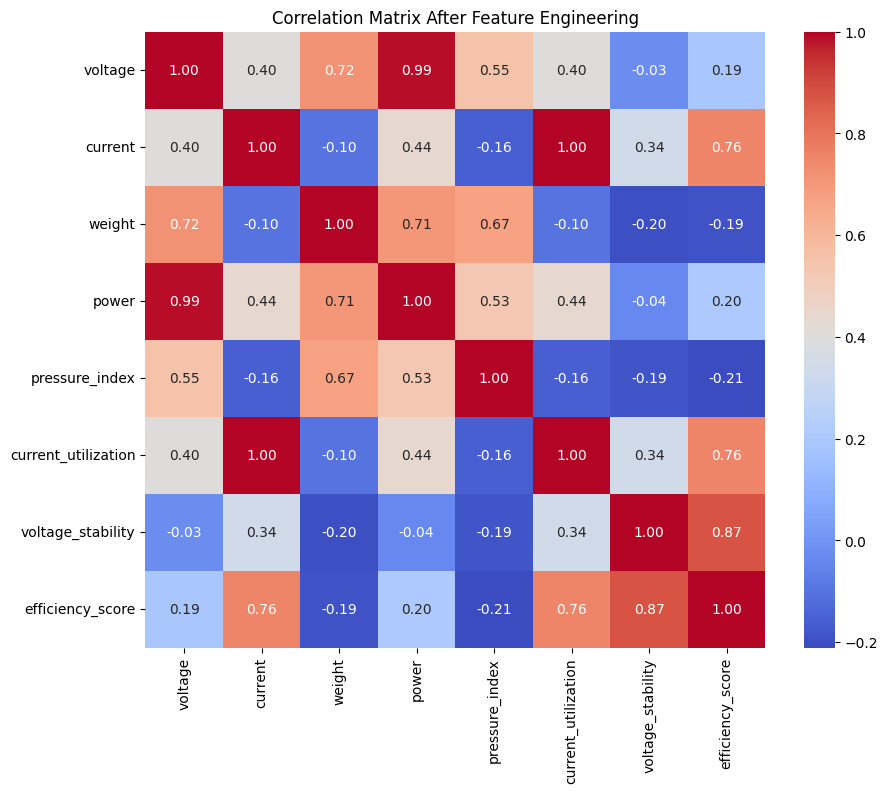

In [29]:
num_df = df.select_dtypes(include=["number"])

corr = num_df.corr()
plt.figure(figsize=(10,8))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix After Feature Engineering")
plt.show()

## Description

The correlation heatmap after feature engineering illustrates the relationships between the original features and the newly engineered features. It helps evaluate how the engineered features contribute to predicting the target variable, **Power**.

## Analysis

- **Voltage** maintains the strongest positive correlation with **Power (0.99)**, making it the most influential predictor.
- **Weight** and **Pressure Index** show strong positive relationships with Power, indicating that user weight significantly affects energy generation.
- **Efficiency Score** has a strong positive correlation with **Voltage Stability (0.87)** and **Current Utilization (0.76)**, confirming the effectiveness of the engineered features.
- **Current Utilization** is perfectly correlated with **Current (1.00)** since it is derived directly from the current values.
- Most engineered features exhibit meaningful relationships with the target variable without introducing excessive redundancy.
- The correlation analysis indicates that the engineered features enhance the dataset and provide additional information for improving machine learning model performance.

<B> Conclusion :</B> The correlation analysis after feature engineering indicates that both original and engineered features contribute valuable information for power prediction. Among the engineered features, Pressure Index and Efficiency Score demonstrate the strongest relationships with the target variable, suggesting their potential importance in improving model performance. The analysis also confirms that feature engineering successfully transformed raw measurements into more informative representations while maintaining meaningful associations with power generation.

## Data Pre-Porcessing

<B> Description </B>

The selected features were preprocessed by encoding categorical variables, splitting the dataset into training and testing sets, and scaling numerical attributes to prepare the data for machine learning model development.

### Step 1: Feature Selection

In [30]:
features = [
    "weight",
    "step_location",
    "weight_class",
    "step_zone",
    "pressure_index",
    "current_utilization",
    "voltage_stability",
    "efficiency_score"
]

x = df[features]

y = df["power"]

### Step 2: Encoding

In [31]:
label_cols = ["step_location","weight_class","step_zone"]

for col in label_cols:
    encoder = LabelEncoder()
    x[col] = encoder.fit_transform(x[col])

### Step 3: Train Test Split

In [32]:
x_train, x_test, y_train, y_test = train_test_split(x, y,test_size=0.20,random_state=42)

### Step 4: Feature Scaling

In [33]:
scaler = StandardScaler()

x_train = scaler.fit_transform(x_train)

x_test = scaler.transform(x_test)

### Analysis

- Voltage and current were excluded from model training to prevent information leakage and ensure a more realistic prediction task.
- Categorical features were encoded into numerical values to make them compatible with machine learning algorithms.
- The dataset was divided into training and testing subsets using an 80:20 ratio.
- Feature scaling was applied to standardize numerical variables and eliminate differences in measurement scales.
- The preprocessing pipeline ensures that all features contribute fairly during model training.
- The prepared dataset is suitable for evaluating the predictive capability of engineered features on power generation.

## Model Development

1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor
4. XGBoost Regressor

#### Linear Regression

In [34]:
lr = LinearRegression()

lr.fit(x_train, y_train)

lr_pred = lr.predict(x_test)

## Model Evaluation

In [35]:
print("R² Score :", r2_score(y_test, lr_pred))
print("MAE      :", mean_absolute_error(y_test, lr_pred))
print("RMSE     :", np.sqrt(mean_squared_error(y_test, lr_pred)))

R² Score : 0.7838747445098011
MAE      : 0.2029203112143764
RMSE     : 0.25942114627767016


#### Decision Tree Regression

In [36]:
dt = DecisionTreeRegressor(random_state=42)

dt.fit(x_train, y_train)

dt_pred = dt.predict(x_test)

## Model Evaluation

In [37]:
print("R² Score :", r2_score(y_test, dt_pred))
print("MAE      :", mean_absolute_error(y_test, dt_pred))
print("RMSE     :", np.sqrt(mean_squared_error(y_test, dt_pred)))

R² Score : 0.9404576566261043
MAE      : 0.0477665
RMSE     : 0.13616502671391065


#### Random Forest Regression

In [38]:
rf = RandomForestRegressor(n_estimators=100, random_state=42)

rf.fit(x_train, y_train)

rf_pred = rf.predict(x_test)

## Model Evaluation

In [39]:
print("R² Score :", r2_score(y_test, rf_pred))
print("MAE      :", mean_absolute_error(y_test, rf_pred))
print("RMSE     :", np.sqrt(mean_squared_error(y_test, rf_pred)))

R² Score : 0.9685462242179502
MAE      : 0.03994434500000001
RMSE     : 0.09896668137787587


#### Graident Boosting Regression

In [40]:
gbr = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)

gbr.fit(x_train, y_train)

gbr_pred = gbr.predict(x_test)

## Model Evaluation

In [41]:
print("R² Score :", r2_score(y_test, gbr_pred))
print("MAE      :", mean_absolute_error(y_test, gbr_pred))
print("RMSE     :", np.sqrt(mean_squared_error(y_test, gbr_pred)))

R² Score : 0.9542019042053816
MAE      : 0.07001228932573496
RMSE     : 0.11941979593394439


In [42]:
results = []

models = {
    "Linear Regression": lr_pred,
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred,
    "Gradient Boosting": gbr_pred
}

for model_name, pred in models.items():

    results.append([
        model_name,
        r2_score(y_test, pred),
        mean_absolute_error(y_test, pred),
        np.sqrt(mean_squared_error(y_test, pred))
    ])

results_df = pd.DataFrame(results, columns=["Model", "R2", "MAE", "RMSE"])

results_df.sort_values(by="R2", ascending=False)

,Model,R2,MAE,RMSE
2,Random Forest,0.968546,0.039944,0.098967
3,Gradient Boosting,0.954202,0.070012,0.119420
1,Decision Tree,0.940458,0.047767,0.136165
0,Linear Regression,0.783875,0.202920,0.259421


## Description

The table compares the performance of four regression models using **R² Score**, **Mean Absolute Error (MAE)**, and **Root Mean Squared Error (RMSE)**. These evaluation metrics help identify the model that provides the most accurate prediction of power generation.

## Analysis

- **Random Forest Regressor** achieved the best overall performance with the **highest R² score (0.9685)** and the **lowest MAE (0.0399)** and **RMSE (0.0990)**, making it the most accurate model.
- **Gradient Boosting Regressor** delivered the second-best performance with an **R² score of 0.9542**, while maintaining low prediction errors.
- **Decision Tree Regressor** achieved a good **R² score of 0.9405**, indicating that it successfully captured the nonlinear relationships present in the dataset.
- **Linear Regression** recorded the lowest **R² score (0.7839)** and the highest prediction errors, suggesting that a simple linear model is insufficient for accurately modeling the data.
- The ensemble learning models (**Random Forest** and **Gradient Boosting**) consistently outperformed the individual regression models.
- Based on the evaluation metrics, **Random Forest Regressor** was selected as the best-performing model for predicting power generation.

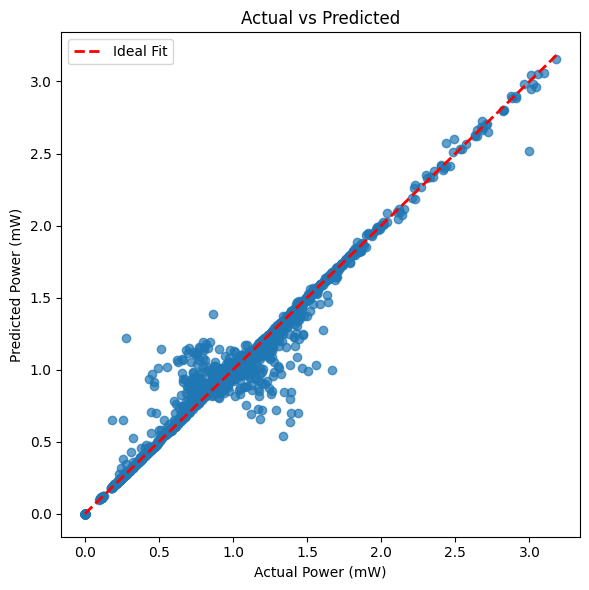

In [43]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))

plt.scatter(y_test, rf_pred, alpha=0.7)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    linewidth=2,
    label='Ideal Fit'
)

plt.xlabel("Actual Power (mW)")
plt.ylabel("Predicted Power (mW)")
plt.title("Actual vs Predicted")
plt.legend()

plt.tight_layout()
plt.show()

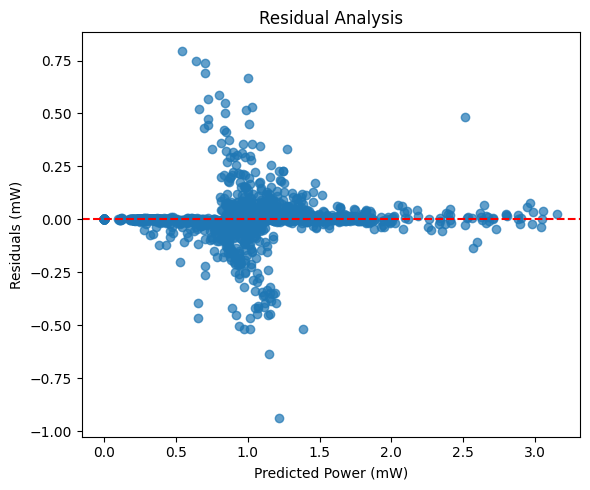

In [44]:
residuals = y_test - rf_pred

plt.figure(figsize=(6,5))

plt.scatter(rf_pred, residuals, alpha=0.7)
plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Power (mW)")
plt.ylabel("Residuals (mW)")
plt.title("Residual Analysis")

plt.tight_layout()
plt.show()

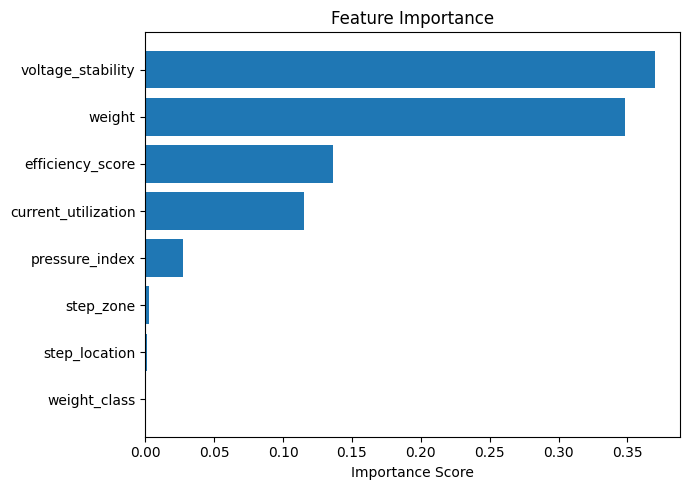

In [45]:
importance = pd.DataFrame({
    "Feature": x.columns,
    "Importance": rf.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(7,5))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Importance Score")
plt.title("Feature Importance")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

### Deployment Code

In [47]:
import pandas as pd
import joblib

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import LabelEncoder

# Load dataset
df = pd.read_csv("dataset_10000.csv")

# Encode step_location
le = LabelEncoder()
df['step_location'] = le.fit_transform(df['step_location'])

# Use ONLY 4 features
X = df[['voltage', 'current', 'weight', 'step_location']]

# Target column (replace with your actual target)
y = df['power']

# Train model
model = LinearRegression()
model.fit(X, y)

# Save model and encoder
joblib.dump(model, "footstep_model.pkl")
joblib.dump(le, "label_encoder.pkl")

print("feature model saved successfully!")

feature model saved successfully!


In [49]:
import pandas as pd
import joblib

# Load model and encoder
model = joblib.load("footstep_model.pkl")
le = joblib.load("label_encoder.pkl")

# User Inputs
voltage = float(input("Enter Voltage (V): "))
current = float(input("Enter Current (A): "))
weight = float(input("Enter Weight (kg): "))
step_location = int(input("Enter Step Location (0/1/2): "))

# Create input dataframe
input_df = pd.DataFrame(
    [[voltage, current, weight, step_location]],
    columns=['voltage', 'current', 'weight', 'step_location']
)

# Predict
predicted_power = model.predict(input_df)

print("\n----- Prediction Result -----")
print(f"Voltage          : {voltage:.2f} V")
print(f"Current          : {current:.2f} A")
print(f"Weight           : {weight:.2f} kg")
print(f"Step Location    : {step_location}")
print(f"Predicted Power  : {predicted_power[0]:.4f}")


----- Prediction Result -----
Voltage          : 24.51 V
Current          : 34.51 A
Weight           : 51.45 kg
Step Location    : 0
Predicted Power  : 1.1294
